# The attractor network behind the exponential map

A check of Sec. 3.1 and Appendix J.1, with no figure in the paper: the exponential map is the
on-manifold dynamics of a gain-modulated continuous attractor network.

The network state evolves as

$$\tau\dot z = U(v)\,z - M\sigma(z),\qquad \sigma(z) = (\|z\|^2 - 1)z \tag{7}$$

with $U$ skew-symmetric and $M$ positive definite. The Lyapunov energy
$E = \tfrac12(\|z\|^2-1)^2$ (Eq. 8) does not increase, since $z^\top U z = 0$ removes the
transport term and $M$ signs the rest,

$$\tau\dot E = -2(\|z\|^2-1)^2 z^\top M z \le 0,$$

so the state reaches the unit hypersphere. There $\sigma(z^*) = 0$, and what remains is pure
transport, $z^*(t) = e^{tU/\tau}z^*(0)$, the exponential map.

The three panels show the energy decaying to zero, the state following $e^{U(t-t^*)}z^*$ from
the time $t^*$ it reaches the manifold, and the state moving away from the static $z^*$, which
is the transport along the manifold.

Forward Euler leaves the state slightly outside the sphere: a step of the transport term
inflates the norm, $\|z + \delta t\,Uz\|^2 = \|z\|^2 + \delta t^2\|Uz\|^2$, and this balances
the inward pull at $\|z\| - 1 = O(\delta t)$, about $10^{-5}$ here. That is why the energy
settles at a small value instead of zero, and the last cell checks that the offset is first
order in $\delta t$.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np

from expmap.attractor import (
    exponential_map_trajectory,
    hypersphere_step,
    lyapunov_energy,
    positive_definite_matrix,
    simulate,
    skew_symmetric_matrix,
)

N = 128
DT = 5e-5
T = 0.03
TAU = 1.0
NUM_TRAJECTORIES = 100
ENERGY_THRESHOLD = 5e-5  # the first time the energy of Eq. 8 falls below this is t*
SEED = 0

STEPS = round(T / DT)
times = np.arange(STEPS) * DT

In [2]:
U = skew_symmetric_matrix(N, seed=SEED)
M = positive_definite_matrix(N, seed=SEED + 1)

assert np.allclose(U, -U.T), "U must be skew-symmetric"
assert np.linalg.eigvalsh(M).min() > 0, "M must be positive definite"

In [3]:
rng = np.random.default_rng(SEED)

energies, exp_deviations, zstar_deviations, t_stars, after_star = [], [], [], [], []

for _ in range(NUM_TRAJECTORIES):
    z0 = rng.uniform(-1, 1, N) * 0.1
    z = simulate(z0, U, M, DT, T, tau=TAU)

    energy = lyapunov_energy(z)
    star = int(np.flatnonzero(energy < ENERGY_THRESHOLD)[0])

    # Pure transport of z* along the manifold, the closed form the state should follow from t*.
    predicted = exponential_map_trajectory(U, z[star], STEPS, DT, star, tau=TAU)

    deviation = np.sum((z - predicted) ** 2, axis=1)
    energies.append(energy)
    exp_deviations.append(deviation)
    after_star.append(deviation[star:].max())
    zstar_deviations.append(np.sum((z - z[star]) ** 2, axis=1))
    t_stars.append(times[star])

energies, exp_deviations, zstar_deviations, t_stars = map(np.array, (energies, exp_deviations, zstar_deviations, t_stars))

print(f"mean t* = {t_stars.mean():.5f}")
print(f"max deviation from the closed form for t >= t*: {max(after_star):.1e}")

mean t* = 0.01250
max deviation from the closed form for t >= t*: 3.9e-05


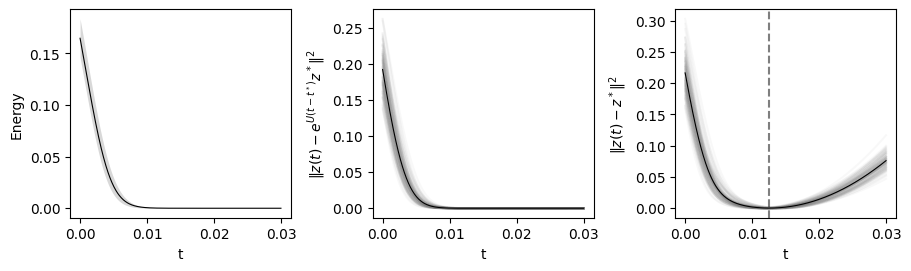

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(9, 2.6), layout="constrained")

mean_energy, std_energy = energies.mean(axis=0), energies.std(axis=0)
axs[0].fill_between(times, mean_energy - std_energy, mean_energy + std_energy, color="gray", alpha=0.3, linewidth=0)
axs[0].plot(times, mean_energy, "k", linewidth=0.8)
axs[0].set_ylabel("Energy")

for ax, deviations, label in [
    (axs[1], exp_deviations, r"$\|z(t) - e^{U(t - t^*)} z^*\|^2$"),
    (axs[2], zstar_deviations, r"$\|z(t) - z^*\|^2$"),
]:
    for deviation in deviations:
        ax.plot(times, deviation, color="gray", alpha=0.05)
    ax.plot(times, deviations.mean(axis=0), "k", linewidth=0.8)
    ax.set_ylabel(label)
axs[2].axvline(t_stars.mean(), color="k", linestyle="--", alpha=0.5)

for ax in axs:
    ax.set_xlabel("t")
    ax.set_xticks([0, 0.01, 0.02, 0.03])

## Checks

The energy does not increase off the manifold, the step on the manifold is pure transport, and
the Euler offset of the norm halves when $\delta t$ halves. The offset needs a longer run than
the figure, since at $T = 0.03$ the finest step has not settled.

In [5]:
z0 = np.random.default_rng(SEED).uniform(-1, 1, N) * 0.1
z = simulate(z0, U, M, DT, T, tau=TAU)
energy = lyapunov_energy(z)

off_manifold = energy[:-1] > 1e-8
print(f"energy non-increasing off the manifold: {np.all(np.diff(energy)[off_manifold] <= 0)}")

unit = z[-1] / np.linalg.norm(z[-1])
print(f"max |step(z*) - U z*| on the manifold: {np.abs(hypersphere_step(unit, U, M) - U @ unit).max():.1e}")

offsets = [np.linalg.norm(simulate(z0, U, M, dt, T=0.06, tau=TAU)[-1]) - 1 for dt in (1e-4, 5e-5, 2.5e-5)]
print(f"||z|| - 1 at dt = 1e-4, 5e-5, 2.5e-5: {', '.join(f'{o:.2e}' for o in offsets)}")
print(f"ratios: {', '.join(f'{a / b:.2f}' for a, b in itertools.pairwise(offsets))}")

energy non-increasing off the manifold: True
max |step(z*) - U z*| on the manifold: 6.7e-15
||z|| - 1 at dt = 1e-4, 5e-5, 2.5e-5: 4.54e-05, 2.27e-05, 1.13e-05
ratios: 2.00, 2.00
